In [1]:
"""
实现的步骤：
1.训练集的准备
2.构造使用的模型
3.设置损失函数和优化器
4.训练模型
"""
import torch
from torch.nn import MSELoss,Linear                     # 平方损失函数和假设函数
from torch.utils.data import DataLoader,TensorDataset   # 数据加载器
from torch import optim                                 # 优化器
from sklearn.datasets import make_regression            # 生成回归模型数据集
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False  # 用来正常显示负号



In [8]:
# 定义数据集
def create_dataset():
    # 参数：n_samples: 样本数量, n_features: 特征数量, noise: 噪声, coef: 权重系数, bias: 偏差, random_state: 随机数种子
    x,y,coef = make_regression(n_samples=100, n_features=1, noise=10, coef=True, bias=14.5, random_state=42)
    x = torch.tensor(x)
    y = torch.tensor(y)
    y = y.reshape(-1,1)
    return x,y,coef

In [9]:
# 构造训练集
def train_model(x,y,coef):
    # 准备tensor dateset
    dataset = TensorDataset(x,y)
    # 准备数据集的加载器
    # 参数：数据集 划分多少个进程 是否打乱顺序
    dataloader = DataLoader(dataset,batch_size=16,shuffle=True)
    # 准备模型
    model = Linear(1,1)
    # 创建损失函数
    loss_fn = MSELoss()
    # 创建优化器
    # 使用梯度下降的方法优化模型的全部参数 后面的参数代表着学习率
    optimizer = optim.SGD(model.parameters(),lr=0.01)
    # 训练模型
    # 列出所有训练时可能用到的变量
    epochs = 100                    # 训练的轮数
    # 开始训练
    for epoch in range(epochs):
        for x_train,y_train in dataloader:
            loss_list = []      # 记录每一轮的损失值
            total_loss = 0.0         # 总损失  
            train_sample = 0.0       # 记录训练样本 
            # 模型选择
            y_pred = model(x_train.to(torch.float32))
            # 计算损失值
            loss = loss_fn(y_pred,y_train)
            # 记录损失值
            total_loss += loss.item()
            train_sample += 1
            # 梯度清零
            optimizer.zero_grad()
            # 反向传播
            loss.backward()
            # 更新权重
            optimizer.step()
        # 打印损失值
        loss_list.append(total_loss/train_sample)
        print(f"epoch:{epoch},loss:{total_loss/train_sample}")
        


In [10]:
x,y,coef = create_dataset()
train_model(x,y,coef)
print(x.shape,y.shape)

epoch:0,loss:1423.6678625019458
epoch:1,loss:1911.6255965496703
epoch:2,loss:1482.794721094675
epoch:3,loss:1994.482202611117
epoch:4,loss:697.8859372873848
epoch:5,loss:306.18150299624443
epoch:6,loss:271.11320009544124
epoch:7,loss:593.4757765207535
epoch:8,loss:231.84297340504992
epoch:9,loss:141.94702113601895
epoch:10,loss:123.9683151261962
epoch:11,loss:98.0108181002004
epoch:12,loss:61.40002343841898
epoch:13,loss:237.7502535049404
epoch:14,loss:81.97331319785216
epoch:15,loss:55.11419512896231
epoch:16,loss:58.580226963092635
epoch:17,loss:109.65126629110969
epoch:18,loss:65.13541433079517
epoch:19,loss:130.76013733426993
epoch:20,loss:30.662761457369307
epoch:21,loss:237.4396851460258
epoch:22,loss:74.18760407204199
epoch:23,loss:110.75408878912651
epoch:24,loss:129.32040324600308
epoch:25,loss:115.89499722576203
epoch:26,loss:87.01323232895717
epoch:27,loss:34.67860761673709
epoch:28,loss:180.43611762693212
epoch:29,loss:175.23317955171527
epoch:30,loss:77.2857418313384
epoch

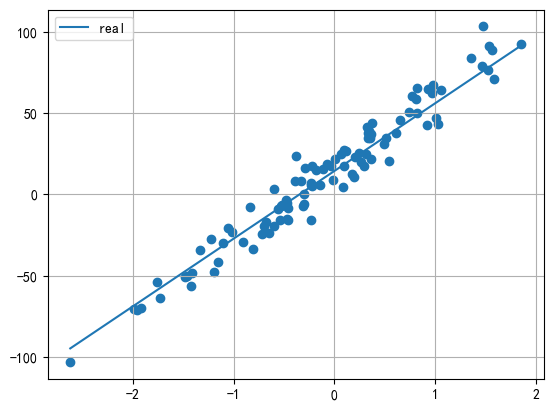

In [47]:
# 绘图查看真实的线性效果
plt.scatter(x, y)
x = torch.linspace(x.min(), x.max(), 100) 
y1 = torch.tensor([v * coef + 14.5 for v in x]) 
plt.plot(x, y1, label='real') 
plt.grid() 
plt.legend() 
plt.show()